# Tree Canopy Segmentation with Detectron2

This notebook demonstrates how to train a Detectron2 model for tree canopy segmentation.

## 1. Install Dependencies

In [ ]:
# Install PyTorch and Detectron2 in Colab
!pip install -q torch torchvision torchaudio
!python -m pip install -q 'git+https://github.com/facebookresearch/detectron2.git'
!pip install -q pycocotools


## 2. Data Download & Extraction

In [ ]:
urls = {
    "train_annotations.json": "https://solafune-dev-v1.s3.us-west-2.amazonaws.com/competitions/tree-canopy-detection/dataset/train_annotations.json",
    "train_images.zip": "https://solafune-dev-v1.s3.us-west-2.amazonaws.com/competitions/tree-canopy-detection/dataset/train_images.zip",
    "evaluation_images.zip": "https://solafune-dev-v1.s3.us-west-2.amazonaws.com/competitions/tree-canopy-detection/dataset/evaluation_images.zip",
    "sample_answer.json": "https://solafune-dev-v1.s3.us-west-2.amazonaws.com/competitions/tree-canopy-detection/dataset/sample_answer.json"
}

# Download each file
for filename, url in urls.items():
    if not os.path.exists(filename):
        print(f"⬇️ Downloading {filename}...")
        response = requests.get(url)
        with open(filename, 'wb') as f:
            f.write(response.content)
    else:
        print(f"✅ {filename} already exists")

# ===============================
# 📦 STEP 3: Unzip Archives
# ===============================
def unzip_file(zip_path, extract_to):
    if not os.path.exists(extract_to):
        os.makedirs(extract_to, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_to)
    print(f"✅ Unzipped {zip_path} → {extract_to}")

# Unzip training and evaluation images
unzip_file("train_images.zip", "train_images")
unzip_file("evaluation_images.zip", "evaluation_images")

# ===============================
# 📄 STEP 4: Load JSON Files
# ===============================
with open('train_annotations.json', 'r') as f:
    train_data = json.load(f)

with open('sample_answer.json', 'r') as f:
    eval_data = json.load(f)

print(f"📊 Number of images in training data: {len(train_data['images'])}")
print(f"📊 Number of images in evaluation data: {len(eval_data['images'])}")



⬇️ Downloading train_annotations.json...
⬇️ Downloading train_images.zip...
⬇️ Downloading evaluation_images.zip...
⬇️ Downloading sample_answer.json...
✅ Unzipped train_images.zip → train_images
✅ Unzipped evaluation_images.zip → evaluation_images
📊 Number of images in training data: 150
📊 Number of images in evaluation data: 150


In [ ]:
import os, json, random, shutil
from pathlib import Path
import numpy as np
from pprint import pprint

# Paths (adjust if your files are in a subfolder)
ROOT = "/content"
DATA_ROOT = os.path.join(ROOT, "dataset")
os.makedirs(DATA_ROOT, exist_ok=True)

# Files expected in current Colab working dir
TRAIN_ZIP = os.path.join(ROOT, "train_images.zip")
EVAL_ZIP = os.path.join(ROOT, "evaluation_images.zip")
RAW_ANN = os.path.join(ROOT, "train_annotations.json")  # your annotation file
# output locations
IMG_DIR = os.path.join(DATA_ROOT, "images")
TRAIN_IMG_DIR = os.path.join(DATA_ROOT, "train_images")
VAL_IMG_DIR = os.path.join(DATA_ROOT, "val_images")

# unzip if needed
import zipfile
if os.path.exists(TRAIN_ZIP):
    print("Unzipping train_images.zip ...")
    with zipfile.ZipFile(TRAIN_ZIP, 'r') as z:
        z.extractall(TRAIN_IMG_DIR)
if os.path.exists(EVAL_ZIP):
    print("Unzipping evaluation_images.zip ...")
    with zipfile.ZipFile(EVAL_ZIP, 'r') as z:
        z.extractall(os.path.join(DATA_ROOT, "evaluation_images"))

# helper: collect all image files
def collect_images(base):
    exts = (".jpg", ".jpeg", ".png", ".tif", ".tiff")
    files = []
    for root, _, filenames in os.walk(base):
        for f in filenames:
            if f.lower().endswith(exts):
                files.append(os.path.relpath(os.path.join(root, f), start=DATA_ROOT))
    return sorted(files)

print("Train image dir:", TRAIN_IMG_DIR, "exists?", os.path.exists(TRAIN_IMG_DIR))


Unzipping train_images.zip ...
Unzipping evaluation_images.zip ...
Train image dir: /content/dataset/train_images exists? True


## 3. Data Conversion (Custom to COCO)

Convert the custom annotation format to the standard COCO format required by Detectron2.

In [ ]:
# if your annotations already follow COCO format (top-level 'annotations' key), we use them directly.
# otherwise we assume the custom format you posted earlier and convert.

COCO_OUT_DIR = os.path.join(DATA_ROOT, "annotations")
os.makedirs(COCO_OUT_DIR, exist_ok=True)
COCO_TRAIN_JSON = os.path.join(COCO_OUT_DIR, "instances_train_coco.json")
COCO_VAL_JSON   = os.path.join(COCO_OUT_DIR, "instances_val_coco.json")
COCO_FULL_JSON  = os.path.join(COCO_OUT_DIR, "instances_full_coco.json")

def is_coco_format(d):
    return isinstance(d, dict) and "annotations" in d and "images" in d and "categories" in d

def convert_custom_to_coco(raw, images_base):
    # raw expected like your earlier message: {"images": [{file_name, width, height, annotations:[{class, segmentation, ...}]}]}
    categories = {}
    cats = []
    anns = []
    imgs = []
    ann_id = 1
    cat_id_counter = 1
    for i, img in enumerate(raw.get("images", [])):
        fname = img["file_name"]
        width = img.get("width")
        height = img.get("height")
        image_id = i+1
        imgs.append({"id": image_id, "file_name": fname, "width": width, "height": height})
        for a in img.get("annotations", []):
            cname = a.get("class", "unknown")
            if cname not in categories:
                categories[cname] = cat_id_counter
                cats.append({"id": cat_id_counter, "name": cname})
                cat_id_counter += 1
            seg = a.get("segmentation", [])
            # ensure segmentation is list of polygons
            if not seg:
                continue
            if isinstance(seg[0], list):
                segs = seg
            else:
                segs = [seg]
            # bbox from first polygon
            xs = segs[0][0::2]; ys = segs[0][1::2]
            x_min, y_min, x_max, y_max = min(xs), min(ys), max(xs), max(ys)
            bbox = [x_min, y_min, x_max - x_min, y_max - y_min]
            # area via shoelace for the first poly
            area = 0
            px = xs; py = ys
            for t in range(len(px)):
                q = (t+1) % len(px)
                area += px[t]*py[q] - px[q]*py[t]
            area = abs(area) / 2.0
            anns.append({
                "id": ann_id,
                "image_id": image_id,
                "category_id": categories[cname],
                "segmentation": segs,
                "area": area,
                "bbox": bbox,
                "iscrowd": 0
            })
            ann_id += 1
    coco = {"images": imgs, "annotations": anns, "categories": cats}
    return coco

# Load raw JSON
with open(RAW_ANN, "r") as f:
    raw = json.load(f)

if is_coco_format(raw):
    print("Annotation file already in COCO format.")
    # write full copy
    with open(COCO_FULL_JSON, "w") as f:
        json.dump(raw, f)
    coco_full = raw
else:
    print("Converting custom format to COCO...")
    coco_full = convert_custom_to_coco(raw, TRAIN_IMG_DIR)
    with open(COCO_FULL_JSON, "w") as f:
        json.dump(coco_full, f)

print("Images found in annotation:", len(coco_full["images"]))
print("Annotations:", len(coco_full["annotations"]))
print("Categories:", coco_full["categories"])


Converting custom format to COCO...
Images found in annotation: 150
Annotations: 38912
Categories: [{'id': 1, 'name': 'individual_tree'}, {'id': 2, 'name': 'group_of_trees'}]


## 4. Dataset Splitting

In [ ]:
# Split by images
imgs = coco_full["images"]
anns = coco_full["annotations"]
random.seed(42)
img_ids = [img["id"] for img in imgs]
random.shuffle(img_ids)
split = int(0.8 * len(img_ids))
train_ids = set(img_ids[:split])
val_ids = set(img_ids[split:])

def filter_coco(images, anns, keep_ids):
    imgs_f = [im for im in images if im["id"] in keep_ids]
    anns_f = [a for a in anns if a["image_id"] in keep_ids]
    return imgs_f, anns_f

train_imgs, train_anns = filter_coco(imgs, anns, train_ids)
val_imgs, val_anns = filter_coco(imgs, anns, val_ids)

cats = coco_full["categories"]

train_coco = {"images": train_imgs, "annotations": train_anns, "categories": cats}
val_coco   = {"images": val_imgs,   "annotations": val_anns,   "categories": cats}

with open(COCO_TRAIN_JSON, "w") as f:
    json.dump(train_coco, f)
with open(COCO_VAL_JSON, "w") as f:
    json.dump(val_coco, f)

print("Train images:", len(train_imgs), "Val images:", len(val_imgs))


Train images: 120 Val images: 30


## 5. Register Dataset in Detectron2


In [ ]:
from detectron2.data.datasets import register_coco_instances
from detectron2.data import MetadataCatalog

TRAIN_NAME = "tree_canopy_train_abs"
VAL_NAME = "tree_canopy_val_abs"

COCO_TRAIN_JSON = "/content/dataset/annotations/instances_train_coco_abs.json"
COCO_VAL_JSON   = "/content/dataset/annotations/instances_val_coco_abs.json"
TRAIN_IMG_DIR   = "/content/dataset"
VAL_IMG_DIR     = "/content/dataset"

# ✅ Correct registration
register_coco_instances(TRAIN_NAME, {}, COCO_TRAIN_JSON, TRAIN_IMG_DIR)
register_coco_instances(VAL_NAME, {}, COCO_VAL_JSON, VAL_IMG_DIR)

# Sanity check
print("Registered datasets:", list(MetadataCatalog.keys()))
print("Train Metadata:", MetadataCatalog.get(TRAIN_NAME))


Registered datasets: ['coco_2014_train', 'coco_2014_val', 'coco_2014_minival', 'coco_2014_valminusminival', 'coco_2017_train', 'coco_2017_val', 'coco_2017_test', 'coco_2017_test-dev', 'coco_2017_val_100', 'keypoints_coco_2014_train', 'keypoints_coco_2014_val', 'keypoints_coco_2014_minival', 'keypoints_coco_2014_valminusminival', 'keypoints_coco_2017_train', 'keypoints_coco_2017_val', 'keypoints_coco_2017_val_100', 'coco_2017_train_panoptic_separated', 'coco_2017_train_panoptic_stuffonly', 'coco_2017_train_panoptic', 'coco_2017_val_panoptic_separated', 'coco_2017_val_panoptic_stuffonly', 'coco_2017_val_panoptic', 'coco_2017_val_100_panoptic_separated', 'coco_2017_val_100_panoptic_stuffonly', 'coco_2017_val_100_panoptic', 'lvis_v1_train', 'lvis_v1_val', 'lvis_v1_test_dev', 'lvis_v1_test_challenge', 'lvis_v0.5_train', 'lvis_v0.5_val', 'lvis_v0.5_val_rand_100', 'lvis_v0.5_test', 'lvis_v0.5_train_cocofied', 'lvis_v0.5_val_cocofied', 'cityscapes_fine_instance_seg_train', 'cityscapes_fine_sem

## 6. Model Configuration & Training

In [ ]:
from detectron2 import model_zoo
from detectron2.config import get_cfg
from detectron2.engine import DefaultTrainer
import os

cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"))
cfg.DATASETS.TRAIN = (TRAIN_NAME,)
cfg.DATASETS.TEST = (VAL_NAME,)
cfg.DATALOADER.NUM_WORKERS = 2

cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")
cfg.SOLVER.IMS_PER_BATCH = 2           # lower if GPU OOM
cfg.SOLVER.BASE_LR = 0.00025
cfg.SOLVER.MAX_ITER = 3000             # change larger for full training
cfg.SOLVER.STEPS = (2000, 2500)
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128
cfg.MODEL.ROI_HEADS.NUM_CLASSES = len(cats)

cfg.OUTPUT_DIR = os.path.join(DATA_ROOT, "detectron2_output")
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()


NameError: name 'TRAIN_NAME' is not defined

## 7. Inference & Visualization

In [ ]:
# Robust inference + debug cell for Detectron2 predictions & visualization
import os, sys, traceback, random
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import importlib

from detectron2.engine import DefaultPredictor
from detectron2.utils.visualizer import Visualizer, ColorMode
from detectron2.data import DatasetCatalog, MetadataCatalog

# --- config checks ------------------------------------------------
print("CHECKS:")
print("  cfg.OUTPUT_DIR:", getattr(cfg, "OUTPUT_DIR", None))
weights_path = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")
print("  expected weights:", weights_path, "exists?", os.path.exists(weights_path))
print("  cfg.MODEL.ROI_HEADS.NUM_CLASSES:", cfg.MODEL.ROI_HEADS.NUM_CLASSES)
print("  VAL dataset name:", VAL_NAME)
print("  #val entries:", len(DatasetCatalog.get(VAL_NAME)))

# utility: robust image reader
def read_image_robust(path):
    # try cv2
    img = None
    try:
        img = cv2.imread(path)
        if img is not None:
            return img
    except Exception as e:
        pass
    # try PIL
    try:
        pil = Image.open(path).convert("RGB")
        arr = np.array(pil)
        # convert RGB -> BGR for detectron2 (predictor expects BGR numpy image)
        return cv2.cvtColor(arr, cv2.COLOR_RGB2BGR)
    except Exception as e:
        pass
    # try tifffile
    try:
        import tifffile
        arr = tifffile.imread(path)
        if arr is None:
            return None
        if arr.ndim == 2:
            arr = np.stack([arr]*3, axis=-1)
        if arr.shape[-1] == 4:
            arr = arr[..., :3]
        # assume arr is RGB
        return cv2.cvtColor(arr.astype("uint8"), cv2.COLOR_RGB2BGR)
    except Exception as e:
        return None

# Make predictor (ensure weights path exists)
if not os.path.exists(weights_path):
    print("ERROR: weights file not found at", weights_path)
    print("If training finished, check cfg.OUTPUT_DIR or the saved checkpoint name.")
else:
    cfg.MODEL.WEIGHTS = weights_path
    cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5
    predictor = DefaultPredictor(cfg)
    print("Predictor created. Device:", cfg.MODEL.DEVICE if hasattr(cfg.MODEL, "DEVICE") else "unknown")

# Visualize a few random validation images
dataset_dicts = DatasetCatalog.get(VAL_NAME)
meta = MetadataCatalog.get(VAL_NAME)
n_show = min(5, len(dataset_dicts))
samples = random.sample(dataset_dicts, n_show)

for idx, d in enumerate(samples):
    f = d["file_name"]
    # construct absolute path if file_name is relative
    if not os.path.isabs(f):
        img_path = os.path.join(DATA_ROOT, f)
    else:
        img_path = f
    print(f"\n[{idx+1}/{n_show}] file_name field: {f}")
    print("  abs path:", img_path)
    print("  exists?:", os.path.exists(img_path))
    if not os.path.exists(img_path):
        # try matching by basename search inside DATA_ROOT
        base = os.path.basename(f)
        print("  Attempting to locate by basename inside DATA_ROOT...")
        import glob
        matches = glob.glob(os.path.join(DATA_ROOT, "**", base), recursive=True)
        print("  matches found:", len(matches))
        if len(matches) == 1:
            img_path = matches[0]
            print("  Using found path:", img_path)
        elif len(matches) > 1:
            print("  Multiple matches found, using first:", matches[0])
            img_path = matches[0]
        else:
            print("  No matching file found; skipping this item.")
            continue

    # read image robustly
    im = read_image_robust(img_path)
    if im is None:
        print("  Failed to read image with cv2/PIL/tifffile. Skipping.")
        continue
    print("  image shape (H,W,C):", im.shape)

    # Run prediction with try/except and print full traceback on error
    try:
        outputs = predictor(im)
    except Exception as e:
        print("  ERROR while running predictor(im):")
        traceback.print_exc()
        # print common diagnostic hints
        print("\n  Common causes:")
        print("   - cfg.MODEL.ROI_HEADS.NUM_CLASSES mismatch vs weights")
        print("   - model weights corrupted")
        print("   - GPU OOM (check runtime logs) or CUDA/device mismatch")
        print("   - image channels or dtype unexpected (we convert to BGR uint8)")
        continue

    # check outputs
    if "instances" not in outputs:
        print("  No 'instances' in outputs:", outputs.keys())
        continue
    inst = outputs["instances"].to("cpu")
    n_inst = len(inst)
    print("  #instances predicted:", n_inst)
    if n_inst == 0:
        print("  No detections above score threshold. Try lowering cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST")
    # visualize predictions
    try:
        v = Visualizer(im[:, :, ::-1], metadata=meta, scale=1.0, instance_mode=ColorMode.IMAGE)
        out = v.draw_instance_predictions(inst)
        plt.figure(figsize=(10,10))
        plt.imshow(out.get_image()[:, :, ::-1])
        plt.axis("off")
        plt.show()
    except Exception as e:
        print("  ERROR during visualization:")
        traceback.print_exc()
        continue

print("\nDone.")


## 8. Generate Submission File


In [ ]:
import os, cv2, json
from detectron2.engine import DefaultPredictor
from detectron2.utils.visualizer import ColorMode
from detectron2.data import MetadataCatalog
from tqdm import tqdm

# Paths
EVAL_DIR = "/content/evaluation_images"
OUT_JSON_PATH = "/content/submission.json"
WEIGHTS = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")

# Load trained model
cfg.MODEL.WEIGHTS = WEIGHTS
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5
predictor = DefaultPredictor(cfg)


In [ ]:
from glob import glob
import numpy as np

image_paths = sorted(glob(os.path.join(EVAL_DIR, "*.*")))

results = {"images": []}

for img_path in tqdm(image_paths, desc="Running inference"):
    im = cv2.imread(img_path)
    if im is None:
        print("Skipping unreadable:", img_path)
        continue

    outputs = predictor(im)
    instances = outputs["instances"].to("cpu")

    file_name = os.path.basename(img_path)
    img_h, img_w = im.shape[:2]
    annotations = []

    # Loop over predicted instances
    for i in range(len(instances)):
        cls_id = int(instances.pred_classes[i])
        cls_name = MetadataCatalog.get(VAL_NAME).thing_classes[cls_id]
        score = float(instances.scores[i])
        mask = instances.pred_masks[i].numpy()

        # Convert binary mask to polygon (RLE/contours)
        contours, _ = cv2.findContours(
            mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )

        if len(contours) == 0:
            continue

        # Convert each contour to flat polygon list
        for contour in contours:
            if len(contour) < 3:
                continue
            poly = contour.flatten().tolist()

            annotations.append({
                "class": cls_name,
                "confidence_score": round(score, 4),
                "segmentation": poly
            })

    results["images"].append({
        "file_name": file_name,
        "width": img_w,
        "height": img_h,
        "annotations": annotations
    })

# Save JSON
with open(OUT_JSON_PATH, "w") as f:
    json.dump(results, f)

print("✅ Submission file saved at:", OUT_JSON_PATH)


In [ ]:
import json
with open(OUT_JSON_PATH) as f:
    data = json.load(f)

print(json.dumps(data["images"][0], indent=2)[:1000])  # show sample


## 5. Register Dataset in Detectron2


Looking for annotation files in: /content/dataset/annotations
Scanned 3 roots, found 2400 image files total.

Summary: matched=120, ambiguous=0, unmatched=0

Wrote remapped train JSON: /content/dataset/annotations/instances_train_coco_remapped.json
Remapped images: 120 annotations: 31899

Registered datasets: tree_canopy_train_remap , tree_canopy_val_remap
[10/23 19:54:10 d2.data.datasets.coco]: Loaded 120 images in COCO format from /content/dataset/annotations/instances_train_coco_remapped.json
Train images registered: 120
[10/23 19:54:11 d2.data.datasets.coco]: Loaded 30 images in COCO format from /content/dataset/annotations/instances_val_coco.json
Val images registered: 30
Classes: ['individual_tree', 'group_of_trees']
[10/23 19:54:11 d2.data.datasets.coco]: Loaded 120 images in COCO format from /content/dataset/annotations/instances_train_coco_remapped.json


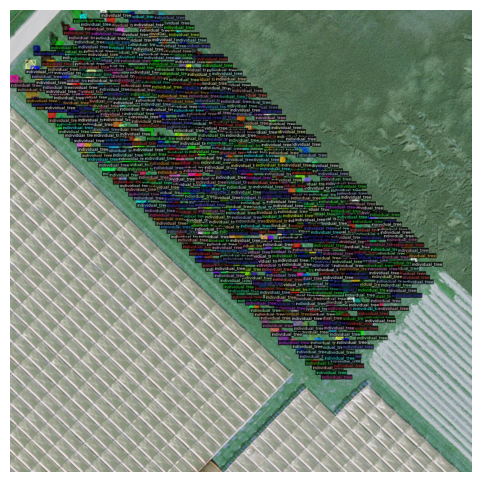

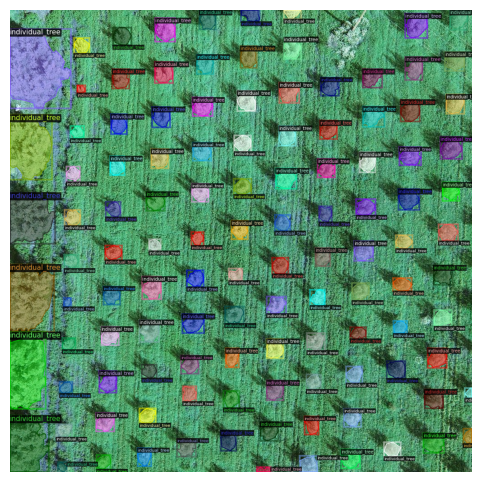


✅ All basenames matched. Use TRAIN_NAME = tree_canopy_train_remap in your cfg and start training.


In [ ]:
# === Auto-find image files (content + drive), remap COCO train JSON to absolute paths, re-register ===
import os, json, glob
from collections import defaultdict
from detectron2.data import DatasetCatalog, MetadataCatalog
from detectron2.data.datasets import register_coco_instances

# ---------- Configure these paths ----------
DATA_ROOT = "/content/dataset"   # where your annotations live
ANN_DIR = os.path.join(DATA_ROOT, "annotations")
TRAIN_JSON = os.path.join(ANN_DIR, "instances_train_coco.json")
VAL_JSON   = os.path.join(ANN_DIR, "instances_val_coco.json")
OUT_TRAIN_JSON = os.path.join(ANN_DIR, "instances_train_coco_remapped.json")
TRAIN_DS_NAME = "tree_canopy_train_remap"
VAL_DS_NAME   = "tree_canopy_val_remap"
# ----------------------------------------------------------------

print("Looking for annotation files in:", ANN_DIR)
if not os.path.isdir(ANN_DIR):
    raise FileNotFoundError(f"Annotation dir not found: {ANN_DIR}. Put your COCO jsons under {ANN_DIR}")

# 1) locate image files under likely roots
search_roots = ["/content/dataset", "/content", "/content/drive"]  # add drive if mounted
exts = (".tif", ".tiff", ".png", ".jpg", ".jpeg", ".jp2")
found = []
for root in search_roots:
    if not os.path.exists(root):
        continue
    for r, dirs, files in os.walk(root):
        for fn in files:
            if fn.lower().endswith(exts):
                found.append(os.path.join(r, fn))

print(f"Scanned {len(search_roots)} roots, found {len(found)} image files total.")

# 2) create basename -> paths map
basename_map = defaultdict(list)
for p in found:
    basename_map[os.path.basename(p)].append(p)

# 3) load COCO train JSON
if not os.path.exists(TRAIN_JSON):
    raise FileNotFoundError(f"Train JSON not found: {TRAIN_JSON}")

with open(TRAIN_JSON, "r") as f:
    coco = json.load(f)

images = coco.get("images", [])
anns = coco.get("annotations", [])
categories = coco.get("categories", [])

matched = []
ambiguous = []
unmatched = []

new_images = []
for im in images:
    fname = im.get("file_name")
    base = os.path.basename(fname)
    cands = basename_map.get(base, [])
    chosen = None
    if len(cands) == 1:
        chosen = cands[0]
    elif len(cands) > 1:
        # prefer ones under DATA_ROOT
        pref = [c for c in cands if os.path.commonpath([os.path.abspath(c), os.path.abspath(DATA_ROOT)]) == os.path.abspath(DATA_ROOT)]
        if pref:
            chosen = pref[0]
        else:
            # pick shortest path as heuristic
            cands.sort(key=len)
            chosen = cands[0]
            ambiguous.append((base, cands))
    else:
        unmatched.append(base)

    if chosen:
        new_im = im.copy()
        new_im["file_name"] = os.path.abspath(chosen)
        new_images.append(new_im)
        matched.append((base, chosen))

print(f"\nSummary: matched={len(matched)}, ambiguous={len(ambiguous)}, unmatched={len(unmatched)}")

if len(matched) == 0:
    # nothing matched — common causes: images not uploaded, or inside zip not extracted, or wrong search_root
    print("\n⚠️ No images matched any COCO basenames. Possible causes:")
    print("  • You haven't uploaded the image files to Colab (upload them to /content or /content/dataset),")
    print("  • Images are in a zip / tar and not extracted,")
    print("  • Images are on Google Drive but Drive not mounted. To mount Drive, run:\n")
    print("    from google.colab import drive\n    drive.mount('/content/drive')\n")
    print("After placing/mounting your images, re-run this cell.")
    # show a sample of COCO basenames to help locate files locally
    print("\nSample basenames from JSON (first 30):")
    for b in [os.path.basename(i.get("file_name")) for i in images[:30]]:
        print(" -", b)
    raise RuntimeError("No images matched. Upload/mount images and re-run.")

# 4) report ambiguous and unmatched
if ambiguous:
    print("\nAmbiguous basename examples (basename -> candidates):")
    for b, cands in ambiguous[:6]:
        print(" -", b, "->", cands[:4])
if unmatched:
    print(f"\nUnmatched basenames: {len(unmatched)} (showing up to 30):")
    for u in unmatched[:30]:
        print(" -", u)

# 5) build remapped COCO JSON keeping same image ids for matched images
old_id_to_new = {}
for im in new_images:
    old_id_to_new[im["id"]] = im

# keep annotations whose image_id was remapped
new_annotations = [a for a in anns if a["image_id"] in old_id_to_new]
new_images_final = [old_id_to_new[iid] for iid in sorted(old_id_to_new.keys())]

coco_remapped = {
    "info": coco.get("info", {"description":"remapped"}),
    "licenses": coco.get("licenses", []),
    "images": new_images_final,
    "annotations": new_annotations,
    "categories": categories
}

with open(OUT_TRAIN_JSON, "w") as f:
    json.dump(coco_remapped, f)
print("\nWrote remapped train JSON:", OUT_TRAIN_JSON)
print("Remapped images:", len(new_images_final), "annotations:", len(new_annotations))

# 6) re-register cleaned dataset
DatasetCatalog.clear(); MetadataCatalog.clear()
register_coco_instances(TRAIN_DS_NAME, {}, OUT_TRAIN_JSON, image_root="")
# for val, keep as-is but try to use absolute if val JSON has relative paths (we keep image_root empty)
register_coco_instances(VAL_DS_NAME, {}, VAL_JSON, image_root="")

# ensure thing_classes set
if not MetadataCatalog.get(TRAIN_DS_NAME).get("thing_classes"):
    cats_list = [c["name"] for c in categories] or ["individual_tree","group_of_trees"]
    MetadataCatalog.get(TRAIN_DS_NAME).set(thing_classes=cats_list)
    MetadataCatalog.get(VAL_DS_NAME).set(thing_classes=cats_list)

print("\nRegistered datasets:", TRAIN_DS_NAME, ",", VAL_DS_NAME)
print("Train images registered:", len(DatasetCatalog.get(TRAIN_DS_NAME)))
print("Val images registered:", len(DatasetCatalog.get(VAL_DS_NAME)))
print("Classes:", MetadataCatalog.get(TRAIN_DS_NAME).thing_classes)

# 7) quick visual check for up to 2 images
try:
    import cv2, matplotlib.pyplot as plt
    from detectron2.utils.visualizer import Visualizer
    samples = DatasetCatalog.get(TRAIN_DS_NAME)[:2]
    if not samples:
        print("No samples available to display.")
    for d in samples:
        p = d["file_name"]
        img = cv2.imread(p)
        if img is None:
            print("Could not read remapped image:", p)
            continue
        v = Visualizer(img[:, :, ::-1], metadata=MetadataCatalog.get(TRAIN_DS_NAME), scale=1.0)
        out = v.draw_dataset_dict(d)
        plt.figure(figsize=(6,6)); plt.imshow(out.get_image()[:, :, ::-1]); plt.axis("off"); plt.show()
except Exception as e:
    print("Visualization skipped (OpenCV/Visualizer error):", e)

# 8) next actions printed
if len(unmatched) == 0:
    print("\n✅ All basenames matched. Use TRAIN_NAME =", TRAIN_DS_NAME, "in your cfg and start training.")
else:
    print(f"\n⚠️ {len(unmatched)} basenames were not found. Inspect the printed list above.")
    print("Next steps:")
    print(" - If images are on Google Drive: mount it with\n       from google.colab import drive\n       drive.mount('/content/drive')\n   then re-run this cell.")
    print(" - If images are zipped: upload and extract them to /content/dataset (or mount Drive).\n - Or move/copy the missing files into /content/dataset and re-run this cell.")


## 5. Register Dataset in Detectron2


In [ ]:
# === TRAIN -> EVAL -> SUBMIT (single cell) ===
import os, json, random, time, cv2, numpy as np
import torch
from detectron2 import model_zoo
from detectron2.config import get_cfg
from detectron2.engine import DefaultTrainer
from detectron2.data import build_detection_train_loader, DatasetCatalog, MetadataCatalog
from detectron2.data import detection_utils as utils
from detectron2.data import transforms as T
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data.datasets import register_coco_instances
from detectron2.utils.visualizer import Visualizer, ColorMode
from detectron2.engine import DefaultPredictor

# ---------- Edit these if you used different names in the remap step ----------
TRAIN_NAME = "tree_canopy_train_remap"   # name created by remap cell
VAL_NAME   = "tree_canopy_val_remap"     # name created by remap cell
DATA_ROOT  = "/content/dataset"
OUTPUT_DIR = os.path.join(DATA_ROOT, "detectron2_output_final")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------- Hyperparams you can tweak ----------
BACKBONE = "R_50"            # "R_50" or "R_101"
IMS_PER_BATCH = 1            # safe for Colab GPU
BASE_LR = 1e-4
MAX_ITER = 3000              # change to 8000 for longer training
STEPS = (2000, 2500)
SCORE_THRESH = 0.5

# ---------- simple augment mapper (robust reading + a few augments) ----------
def aug_mapper(dataset_dict):
    d = dataset_dict.copy()
    img_path = d["file_name"]
    if not os.path.isabs(img_path):
        img_path = os.path.join(DATA_ROOT, img_path)
    image = utils.read_image(img_path, format="BGR")
    aug_list = [
        T.ResizeShortestEdge(short_edge_length=(800, 1024), max_size=1600, sample_style='choice'),
        T.RandomFlip(prob=0.5, horizontal=True, vertical=False),
        # small rotation may help:
        T.RandomRotation(angle=[-10,10]),
    ]
    aug_input = T.AugInput(image)
    transforms = T.AugmentationList(aug_list)(aug_input)
    image = aug_input.image
    d["image"] = torch.as_tensor(np.ascontiguousarray(image.transpose(2,0,1)))
    annos = [utils.transform_instance_annotations(obj, transforms, image.shape[:2]) for obj in d.pop("annotations", [])]
    d["instances"] = utils.annotations_to_instances(annos, image.shape[:2])
    return d

# ---------- Custom trainer using aug_mapper ----------
class MyTrainer(DefaultTrainer):
    @classmethod
    def build_train_loader(cls, cfg):
        return build_detection_train_loader(cfg, mapper=aug_mapper)
    @classmethod
    def build_evaluator(cls, cfg, dataset_name, output_folder=None):
        if output_folder is None:
            output_folder = os.path.join(cfg.OUTPUT_DIR, "inference")
        return COCOEvaluator(dataset_name, cfg, False, output_folder)

# ---------- Build config ----------
cfg = get_cfg()
cfg_file = f"COCO-InstanceSegmentation/mask_rcnn_{BACKBONE}_FPN_3x.yaml"
cfg.merge_from_file(model_zoo.get_config_file(cfg_file))

cfg.DATASETS.TRAIN = (TRAIN_NAME,)
cfg.DATASETS.TEST  = (VAL_NAME,)
cfg.DATALOADER.NUM_WORKERS = 2

cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(cfg_file)  # start from COCO weights
cfg.SOLVER.IMS_PER_BATCH = IMS_PER_BATCH
cfg.SOLVER.BASE_LR = BASE_LR
cfg.SOLVER.MAX_ITER = MAX_ITER
cfg.SOLVER.STEPS = STEPS
cfg.SOLVER.WARMUP_ITERS = 500
cfg.SOLVER.AMP.ENABLED = True

cfg.INPUT.MIN_SIZE_TRAIN = (800, 1024)
cfg.INPUT.MAX_SIZE_TRAIN = 1600
cfg.INPUT.MIN_SIZE_TEST = 1024
cfg.INPUT.MAX_SIZE_TEST = 1600

# num classes from metadata
num_classes = len(MetadataCatalog.get(TRAIN_NAME).get("thing_classes", []))
if num_classes == 0:
    # try reading json categories
    annp = os.path.join(DATA_ROOT, "annotations")
    possible = [p for p in os.listdir(annp) if p.endswith(".json")]
    # fallback: set 2 classes (individual_tree, group_of_trees)
    num_classes = 2
cfg.MODEL.ROI_HEADS.NUM_CLASSES = num_classes
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128

cfg.OUTPUT_DIR = OUTPUT_DIR
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

print("CONFIG SUMMARY")
print("TRAIN:", TRAIN_NAME, "VAL:", VAL_NAME)
print("OUTPUT_DIR:", cfg.OUTPUT_DIR)
print("NUM_CLASSES:", cfg.MODEL.ROI_HEADS.NUM_CLASSES)
print("IMS_PER_BATCH:", cfg.SOLVER.IMS_PER_BATCH, "MAX_ITER:", cfg.SOLVER.MAX_ITER)

# ---------- Start training ----------
trainer = MyTrainer(cfg)
trainer.resume_or_load(resume=False)
print("\nStarting training... (Ctrl-C to stop early)\n")
trainer.train()

# ---------- After training: evaluate on validation ----------
print("\nTraining finished. Running evaluation on validation set...")
evaluator = COCOEvaluator(VAL_NAME, cfg, False, output_dir=os.path.join(cfg.OUTPUT_DIR, "eval"))
val_loader = build_detection_train_loader(cfg, mapper=None)  # wrong loader -> use test loader below
from detectron2.data import build_detection_test_loader
val_loader = build_detection_test_loader(cfg, VAL_NAME)
res = inference_on_dataset(trainer.model, val_loader, evaluator)
print("EVAL RESULTS:", json.dumps(res, indent=2))

# ---------- Build predictor for inference and create submission JSON ----------
cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = SCORE_THRESH
predictor = DefaultPredictor(cfg)

# We'll generate predictions for the validation set (or change to test set if you have test images)
dataset_dicts = DatasetCatalog.get(VAL_NAME)
submission = {"images": []}
for d in dataset_dicts:
    img_path = d["file_name"]
    if not os.path.isabs(img_path):
        img_path = os.path.join(DATA_ROOT, img_path)
    im = cv2.imread(img_path)
    if im is None:
        print("WARN: could not read", img_path); continue
    outputs = predictor(im)
    instances = outputs["instances"].to("cpu")
    ann_list = []
    # convert masks -> polygons (simple contour on first mask)
    for i in range(len(instances)):
        score = float(instances.scores[i].item())
        mask = instances.pred_masks[i].numpy().astype("uint8") * 255
        # find contours and flatten first one
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            continue
        # pick the largest contour
        contour = max(contours, key=cv2.contourArea)
        poly = contour.flatten().tolist()
        if len(poly) < 6:
            continue
        ann_list.append({
            "class": "individual_tree",               # if multiple classes, map according to MetadataCatalog
            "confidence_score": score,
            "segmentation": poly
        })
    submission["images"].append({
        "file_name": os.path.basename(img_path),
        "width": int(im.shape[1]),
        "height": int(im.shape[0]),
        "scene_type": "unknown",
        "cm_resolution": 40,
        "annotations": ann_list
    })

SUB_OUT = os.path.join(DATA_ROOT, "submission_from_detectron2.json")
with open(SUB_OUT, "w") as f:
    json.dump(submission, f)
print("Submission written to:", SUB_OUT)

# ---------- Small visual check of a random prediction ----------
try:
    import random
    sample = random.choice(dataset_dicts)
    p = sample["file_name"] if os.path.isabs(sample["file_name"]) else os.path.join(DATA_ROOT, sample["file_name"])
    img = cv2.imread(p)
    out = predictor(img)
    v = Visualizer(img[:, :, ::-1], metadata=MetadataCatalog.get(VAL_NAME), scale=1.0, instance_mode=ColorMode.IMAGE)
    v = v.draw_instance_predictions(out["instances"].to("cpu"))
    import matplotlib.pyplot as plt
    plt.figure(figsize=(8,8)); plt.imshow(v.get_image()[:, :, ::-1]); plt.axis("off"); plt.show()
except Exception as e:
    print("Visual check failed:", e)

print("\nAll done. If you want to tune: change MAX_ITER, augmentations, backbone (R_101), or ROI_HEADS.BATCH_SIZE_PER_IMAGE.")


CONFIG SUMMARY
TRAIN: tree_canopy_train_remap VAL: tree_canopy_val_remap
OUTPUT_DIR: /content/dataset/detectron2_output_final
NUM_CLASSES: 2
IMS_PER_BATCH: 1 MAX_ITER: 3000
[10/23 19:56:55 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d

roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}
roi_heads.mask_head.predictor.{bias, weight}



Starting training... (Ctrl-C to stop early)

[10/23 19:56:57 d2.engine.train_loop]: Starting training from iteration 0


/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/torch/functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4322.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/usr/local/lib/python3.12/dist-packages/torch/optim/lr_scheduler.py:192: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-a

[10/23 19:57:08 d2.utils.events]:  eta: 0:13:43  iter: 19  total_loss: 5.672  loss_cls: 1.122  loss_box_reg: 0.2521  loss_mask: 0.6932  loss_rpn_cls: 3.186  loss_rpn_loc: 0.3885    time: 0.3224  last_time: 0.1451  data_time: 0.0286  last_data_time: 0.0006   lr: 3.8962e-06  max_mem: 6152M


/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/dete

... (294 outputs left out)

[10/23 20:07:54 d2.utils.events]:  eta: 0:00:04  iter: 2979  total_loss: 1.813  loss_cls: 0.4495  loss_box_reg: 0.423  loss_mask: 0.3417  loss_rpn_cls: 0.1884  loss_rpn_loc: 0.3022    time: 0.2157  last_time: 0.1961  data_time: 0.0078  last_data_time: 0.0034   lr: 1e-06  max_mem: 9817M


/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/dete

[10/23 20:08:02 d2.utils.events]:  eta: 0:00:00  iter: 2999  total_loss: 1.544  loss_cls: 0.3589  loss_box_reg: 0.4105  loss_mask: 0.3421  loss_rpn_cls: 0.1522  loss_rpn_loc: 0.2573    time: 0.2156  last_time: 0.1762  data_time: 0.0063  last_data_time: 0.0008   lr: 1e-06  max_mem: 9817M
[10/23 20:08:02 d2.engine.hooks]: Overall training speed: 2998 iterations in 0:10:46 (0.2156 s / it)
[10/23 20:08:02 d2.engine.hooks]: Total training time: 0:10:59 (0:00:13 on hooks)
[10/23 20:08:02 d2.data.datasets.coco]: Loaded 30 images in COCO format from /content/dataset/annotations/instances_val_coco.json
[10/23 20:08:02 d2.data.build]: Distribution of instances among all 2 categories:
|   category    | #instances   |   category    | #instances   |
|:-------------:|:-------------|:-------------:|:-------------|
| individual_.. | 6304         | group_of_tr.. | 709          |
|               |              |               |              |
|     total     | 7013         |               |             

FileNotFoundError: Caught FileNotFoundError in DataLoader worker process 0.
Original Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/worker.py", line 349, in _worker_loop
    data = fetcher.fetch(index)  # type: ignore[possibly-undefined]
           ^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/fetch.py", line 52, in fetch
    data = [self.dataset[idx] for idx in possibly_batched_index]
            ~~~~~~~~~~~~^^^^^
  File "/usr/local/lib/python3.12/dist-packages/detectron2/data/common.py", line 125, in __getitem__
    data = self._map_func(self._dataset[cur_idx])
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/detectron2/utils/serialize.py", line 26, in __call__
    return self._obj(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/detectron2/data/dataset_mapper.py", line 154, in

## 5. Register Dataset in Detectron2


In [ ]:
# === Fix missing-image problem (remap train+val COCO JSONs to absolute paths) and restart training ===
import os, json, glob, sys, traceback
from collections import defaultdict
from detectron2.data import DatasetCatalog, MetadataCatalog
from detectron2.data.datasets import register_coco_instances

# ----- Edit these if your layout is different -----
DATA_ROOT = "/content/dataset"
ANN_DIR = os.path.join(DATA_ROOT, "annotations")
TRAIN_JSON = os.path.join(ANN_DIR, "instances_train_coco.json")
VAL_JSON   = os.path.join(ANN_DIR, "instances_val_coco.json")
OUT_TRAIN = os.path.join(ANN_DIR, "instances_train_coco_remapped.json")
OUT_VAL   = os.path.join(ANN_DIR, "instances_val_coco_remapped.json")
# names used to register datasets
TRAIN_NAME = "tree_canopy_train_remapped"
VAL_NAME   = "tree_canopy_val_remapped"
# where to search for image files (add more roots if needed)
SEARCH_ROOTS = ["/content/dataset", "/content", "/content/drive"]
IMAGE_EXTS = (".tif", ".tiff", ".png", ".jpg", ".jpeg", ".jp2")
# -------------------------------------------------

# sanity checks
if not os.path.isdir(ANN_DIR):
    raise FileNotFoundError(f"Annotation dir not found: {ANN_DIR}")

if not os.path.exists(TRAIN_JSON) or not os.path.exists(VAL_JSON):
    raise FileNotFoundError(f"Train/Val JSONs not found in {ANN_DIR}. Found: {glob.glob(os.path.join(ANN_DIR,'*.json'))}")

print("Searching image files under:", SEARCH_ROOTS)
found_files = []
for root in SEARCH_ROOTS:
    if not os.path.exists(root):
        continue
    for dirpath, dirnames, filenames in os.walk(root):
        for fn in filenames:
            if fn.lower().endswith(IMAGE_EXTS):
                found_files.append(os.path.join(dirpath, fn))
print("Found image files:", len(found_files))

# build basename -> paths map
basename_map = defaultdict(list)
for p in found_files:
    basename_map[os.path.basename(p)].append(p)

def remap_json(in_json_path, out_json_path):
    with open(in_json_path, "r") as f:
        coco = json.load(f)
    images = coco.get("images", [])
    anns = coco.get("annotations", [])
    categories = coco.get("categories", [])

    matched = []
    ambiguous = []
    unmatched = []
    new_images = []
    for im in images:
        orig_fname = im.get("file_name")
        base = os.path.basename(orig_fname)
        cands = basename_map.get(base, [])
        chosen = None
        if len(cands) == 1:
            chosen = cands[0]
        elif len(cands) > 1:
            # prefer candidate under DATA_ROOT
            pref = [c for c in cands if os.path.commonpath([os.path.abspath(c), os.path.abspath(DATA_ROOT)]) == os.path.abspath(DATA_ROOT)]
            if pref:
                chosen = pref[0]
            else:
                # pick shortest path (heuristic) and mark ambiguous
                cands.sort(key=len)
                chosen = cands[0]
                ambiguous.append((base, cands))
        else:
            # try substring fallback: maybe filenames were renamed slightly (rare)
            subs = [p for p in found_files if base.split('.')[0] in os.path.basename(p)]
            if len(subs) == 1:
                chosen = subs[0]
            elif len(subs) > 1:
                subs.sort(key=len)
                chosen = subs[0]
                ambiguous.append((base, subs))
            else:
                unmatched.append(base)
                chosen = None

        if chosen:
            new_im = im.copy()
            new_im["file_name"] = os.path.abspath(chosen)
            new_images.append(new_im)
            matched.append((base, chosen))

    # build new annotations only for matched images
    matched_ids = set(im["id"] for im in new_images)
    new_anns = [a for a in anns if a["image_id"] in matched_ids]

    remapped = {
        "info": coco.get("info", {"description": "remapped"}),
        "licenses": coco.get("licenses", []),
        "images": new_images,
        "annotations": new_anns,
        "categories": categories
    }

    with open(out_json_path, "w") as f:
        json.dump(remapped, f)

    return {
        "matched": len(matched),
        "ambiguous": ambiguous,
        "unmatched": unmatched,
        "images_kept": len(new_images),
        "annotations_kept": len(new_anns)
    }

print("Remapping TRAIN JSON...")
rtrain = remap_json(TRAIN_JSON, OUT_TRAIN)
print("Remapping VAL JSON...")
rval = remap_json(VAL_JSON, OUT_VAL)

print("\nTrain remap:", rtrain)
print("Val remap:  ", rval)

# if any unmatched in either, stop and report
all_unmatched = set(rtrain["unmatched"] + rval["unmatched"])
if len(all_unmatched) > 0:
    print("\n⚠️ There are unmatched basenames — training will NOT start until these are fixed.")
    print("Unmatched (showing up to 100):")
    for i, u in enumerate(list(all_unmatched)[:100]):
        print(f" - {u}")
    print("\nPossible fixes:")
    print(" • Move or extract your images into /content/dataset or mount Drive (drive.mount('/content/drive')) and re-run this cell.")
    print(" • If images exist but with different names, rename them to match COCO file_name basenames.")
    raise RuntimeError("Unmatched image basenames remain. Fix them and re-run.")

# All matched -> register the remapped jsons (clear previous registration)
DatasetCatalog.clear(); MetadataCatalog.clear()
register_coco_instances(TRAIN_NAME, {}, OUT_TRAIN, image_root="")
register_coco_instances(VAL_NAME, {}, OUT_VAL, image_root="")

# ensure thing_classes
from detectron2.data import MetadataCatalog as MC
meta = MC.get(TRAIN_NAME)
if not meta.get("thing_classes"):
    with open(OUT_TRAIN, "r") as f:
        tmp = json.load(f)
    cats = [c["name"] for c in tmp.get("categories", [])] or ["individual_tree","group_of_trees"]
    MC.get(TRAIN_NAME).set(thing_classes=cats)
    MC.get(VAL_NAME).set(thing_classes=cats)

print("\n✅ Remapped & registered datasets:")
print(" TRAIN_NAME:", TRAIN_NAME, " ->", len(DatasetCatalog.get(TRAIN_NAME)), "images")
print(" VAL_NAME:  ", VAL_NAME,   " ->", len(DatasetCatalog.get(VAL_NAME)), "images")
print(" Classes:", MC.get(TRAIN_NAME).thing_classes)

# ----------------- If remap succeeded, (re)start training -----------------
# build training cfg and start trainer (safe settings similar to before)
try:
    from detectron2 import model_zoo
    from detectron2.config import get_cfg
    from detectron2.engine import DefaultTrainer
    from detectron2.data import build_detection_train_loader
    from detectron2.data import detection_utils as utils
    from detectron2.data import transforms as T
    import torch, numpy as np

    # # custom mapper similar to earlier (reads absolute paths)
    # def aug_mapper(dataset_dict):
    #     d = dataset_dict.copy()
    #     img_path = d["file_name"]
    #     if not os.path.isabs(img_path):
    #         img_path = os.path.join(DATA_ROOT, img_path)
    #     image = utils.read_image(img_path, format="BGR")
    #     aug_list = [
    #         T.ResizeShortestEdge(short_edge_length=(800,1024), max_size=1600, sample_style='choice'),
    #         T.RandomFlip(prob=0.5, horizontal=True, vertical=False),
    #         T.RandomRotation(angle=[-10,10]),
    #     ]
    #     aug_input = T.AugInput(image)
    #     transforms = T.AugmentationList(aug_list)(aug_input)
    #     image = aug_input.image
    #     d["image"] = torch.as_tensor(np.ascontiguousarray(image.transpose(2,0,1)))
    #     annos = [utils.transform_instance_annotations(obj, transforms, image.shape[:2]) for obj in d.pop("annotations", [])]
    #     d["instances"] = utils.annotations_to_instances(annos, image.shape[:2])
    #     return d

    # class MyTrainer(DefaultTrainer):
    #     @classmethod
    #     def build_train_loader(cls, cfg):
    #         return build_detection_train_loader(cfg, mapper=aug_mapper)

    # build cfg
    cfg = get_cfg()
    cfg_file = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
    cfg.merge_from_file(model_zoo.get_config_file(cfg_file))

    cfg.DATASETS.TRAIN = (TRAIN_NAME,)
    cfg.DATASETS.TEST = (VAL_NAME,)
    cfg.DATALOADER.NUM_WORKERS = 2
    cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(cfg_file)
    cfg.SOLVER.IMS_PER_BATCH = 1
    cfg.SOLVER.BASE_LR = 1e-4
    cfg.SOLVER.MAX_ITER = 3000
    cfg.SOLVER.STEPS = (2000, 2500)
    cfg.SOLVER.WARMUP_ITERS = 500
    cfg.SOLVER.AMP.ENABLED = True
    cfg.INPUT.MIN_SIZE_TRAIN = (800,1024)
    cfg.INPUT.MAX_SIZE_TRAIN = 1600
    cfg.INPUT.MIN_SIZE_TEST = 1024
    cfg.INPUT.MAX_SIZE_TEST = 1600
    cfg.MODEL.ROI_HEADS.NUM_CLASSES = len(MC.get(TRAIN_NAME).thing_classes)
    cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128
    cfg.OUTPUT_DIR = os.path.join(DATA_ROOT, "detectron2_output_remapped")
    os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

    print("\nStarting training with remapped datasets. OUTPUT_DIR:", cfg.OUTPUT_DIR)
    trainer = MyTrainer(cfg)
    trainer.resume_or_load(resume=False)
    trainer.train()

except Exception as e:
    print("Error while building cfg / starting training:")
    traceback.print_exc()
    raise


Searching image files under: ['/content/dataset', '/content', '/content/drive']
Found image files: 2400
Remapping TRAIN JSON...
Remapping VAL JSON...

Train remap: {'matched': 120, 'ambiguous': [], 'unmatched': [], 'images_kept': 120, 'annotations_kept': 31899}
Val remap:   {'matched': 30, 'ambiguous': [], 'unmatched': [], 'images_kept': 30, 'annotations_kept': 7013}

✅ Remapped & registered datasets:
[10/23 20:10:59 d2.data.datasets.coco]: Loaded 120 images in COCO format from /content/dataset/annotations/instances_train_coco_remapped.json
 TRAIN_NAME: tree_canopy_train_remapped  -> 120 images
[10/23 20:11:00 d2.data.datasets.coco]: Loaded 30 images in COCO format from /content/dataset/annotations/instances_val_coco_remapped.json
 VAL_NAME:   tree_canopy_val_remapped  -> 30 images
 Classes: ['individual_tree', 'group_of_trees']

Starting training with remapped datasets. OUTPUT_DIR: /content/dataset/detectron2_output_remapped
[10/23 20:11:01 d2.engine.defaults]: Model:
GeneralizedRCNN(

/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:474: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  grad_scaler = GradScaler()
roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}
roi_heads.mask_head.predictor.{bias, weight}


[10/23 20:11:01 d2.engine.train_loop]: Starting training from iteration 0


/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/torch/optim/lr_scheduler.py:192: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/de

[10/23 20:11:06 d2.utils.events]:  eta: 0:10:14  iter: 19  total_loss: 5.832  loss_cls: 0.9987  loss_box_reg: 0.2863  loss_mask: 0.6939  loss_rpn_cls: 3.301  loss_rpn_loc: 0.4086    time: 0.2019  last_time: 0.1387  data_time: 0.0214  last_data_time: 0.0005   lr: 3.8962e-06  max_mem: 9817M


/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/dete

... (293 outputs left out)

/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/dete

[10/23 20:21:43 d2.utils.events]:  eta: 0:00:04  iter: 2979  total_loss: 1.809  loss_cls: 0.4152  loss_box_reg: 0.4093  loss_mask: 0.3314  loss_rpn_cls: 0.1464  loss_rpn_loc: 0.2811    time: 0.2146  last_time: 0.1536  data_time: 0.0044  last_data_time: 0.0046   lr: 1e-06  max_mem: 9854M


/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/dete

[10/23 20:21:54 d2.utils.events]:  eta: 0:00:00  iter: 2999  total_loss: 1.633  loss_cls: 0.3758  loss_box_reg: 0.4186  loss_mask: 0.3507  loss_rpn_cls: 0.1449  loss_rpn_loc: 0.2517    time: 0.2146  last_time: 0.2763  data_time: 0.0063  last_data_time: 0.0021   lr: 1e-06  max_mem: 9854M
[10/23 20:21:55 d2.engine.hooks]: Overall training speed: 2998 iterations in 0:10:43 (0.2146 s / it)
[10/23 20:21:55 d2.engine.hooks]: Total training time: 0:10:52 (0:00:09 on hooks)
[10/23 20:21:55 d2.data.datasets.coco]: Loaded 30 images in COCO format from /content/dataset/annotations/instances_val_coco_remapped.json
[10/23 20:21:55 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(1024, 1024), max_size=1600, sample_style='choice')]
[10/23 20:21:55 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[10/23 20:21:55 d2.data.common]: Serializing 30 elements to byte tensors and concatenating 

Loading weights: /content/dataset/detectron2_output_remapped/model_final.pth
WARNING [10/23 20:25:27 d2.evaluation.coco_evaluation]: COCO Evaluator instantiated using config, this is deprecated behavior. Please pass in explicit arguments instead.
[10/23 20:25:27 d2.data.datasets.coco]: Loaded 30 images in COCO format from /content/dataset/annotations/instances_val_coco_remapped.json
[10/23 20:25:27 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(1024, 1024), max_size=1600, sample_style='choice')]
[10/23 20:25:27 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[10/23 20:25:27 d2.data.common]: Serializing 30 elements to byte tensors and concatenating them all ...
[10/23 20:25:27 d2.data.common]: Serialized dataset takes 2.28 MiB
Running evaluation on dataset: tree_canopy_val_remapped
[10/23 20:25:27 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading fro

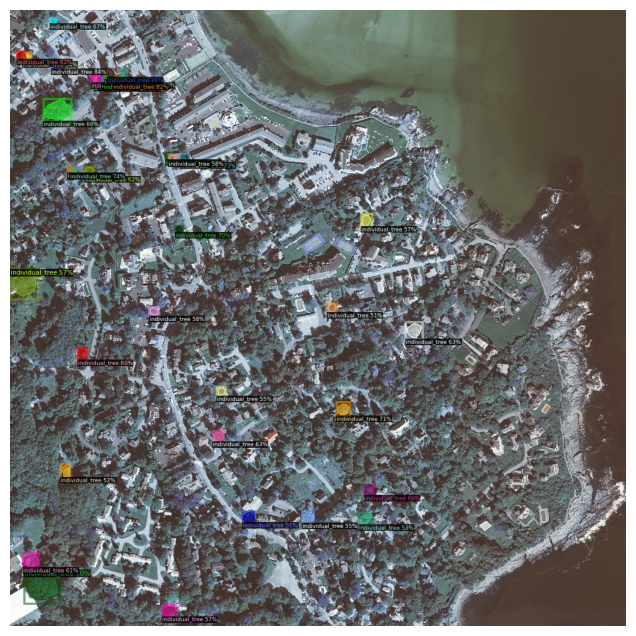


Done. Files written to the eval folder and submission JSON saved.


In [ ]:
# === EVAL + TTA + submission generation (single cell) ===
import os, json, time, cv2, numpy as np
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader, DatasetCatalog, MetadataCatalog
from detectron2.engine import DefaultPredictor
from detectron2.utils.visualizer import Visualizer, ColorMode
from detectron2.data import MetadataCatalog
from detectron2.evaluation import DatasetEvaluator
from detectron2.modeling import build_model
from detectron2.checkpoint import DetectionCheckpointer

# ---- Edit these if your names/paths are different ----
VAL_NAME = "tree_canopy_val_remapped"       # validation dataset name you registered
OUTPUT_DIR = cfg.OUTPUT_DIR                 # keep same output dir used for training
DATA_ROOT = "/content/dataset"
SCORE_THRESH = 0.5
SUBMISSION_OUT = os.path.join(DATA_ROOT, "submission_from_eval.json")
COCO_RESULTS_OUT = os.path.join(OUTPUT_DIR, "eval", "coco_instances_results.json")
USE_TTA = False      # set True to run TTA eval (slower but usually better)
# -----------------------------------------------------

os.makedirs(os.path.join(OUTPUT_DIR, "eval"), exist_ok=True)

# 1) Load trained weights (prefer model_final.pth)
weights_path = os.path.join(OUTPUT_DIR, "model_final.pth")
if not os.path.exists(weights_path):
    # find latest checkpoint in OUTPUT_DIR
    ckps = [os.path.join(OUTPUT_DIR, f) for f in os.listdir(OUTPUT_DIR) if f.endswith(".pth") or f.endswith(".pth.tar")]
    if ckps:
        weights_path = sorted(ckps, key=os.path.getmtime)[-1]
        print("Using latest checkpoint:", weights_path)
    else:
        # try detectron2 default last_checkpoint file
        last = os.path.join(OUTPUT_DIR, "last_checkpoint")
        if os.path.exists(last):
            with open(last, "r") as f:
                weights_path = f.read().strip()
        else:
            raise FileNotFoundError("No checkpoint found in OUTPUT_DIR: " + OUTPUT_DIR)

print("Loading weights:", weights_path)
cfg.MODEL.WEIGHTS = weights_path
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = SCORE_THRESH

# 2) Build evaluator + dataloader, then run inference
evaluator = COCOEvaluator(VAL_NAME, cfg, False, output_dir=os.path.join(OUTPUT_DIR, "eval"))
val_loader = build_detection_test_loader(cfg, VAL_NAME)

print("Running evaluation on dataset:", VAL_NAME)
start = time.time()
from detectron2.engine import DefaultPredictor
from detectron2.evaluation import inference_on_dataset
# if trainer exists and has model, use it; otherwise build model from cfg
try:
    model = trainer.model
    # ensure weights loaded into model
    DetectionCheckpointer(model).load(weights_path)
except Exception:
    model = build_model(cfg)
    DetectionCheckpointer(model).load(weights_path)
res = inference_on_dataset(model, val_loader, evaluator)
dur = time.time() - start
print(f"EVAL completed in {dur:.1f}s")
print("EVAL RESULTS (dict):")
print(json.dumps(res, indent=2))

# Save a copy of the COCO results (if produced by evaluator)
coco_json_path = os.path.join(OUTPUT_DIR, "eval", "coco_instances_results.json")
if os.path.exists(coco_json_path):
    print("COCO results saved at:", coco_json_path)
else:
    print("COCO results file not found at expected path:", coco_json_path)

# 3) Optional: Test-time augmentation evaluation (Detectron2 convenience)
if USE_TTA:
    print("\nRunning TTA evaluation (this is slower)...")
    from detectron2.engine import DefaultTrainer
    from detectron2.modeling.test_time_augment import GeneralizedRCNNWithTTA
    tta_model = GeneralizedRCNNWithTTA(cfg, model)
    tta_evaluator = COCOEvaluator(VAL_NAME, cfg, False, output_dir=os.path.join(OUTPUT_DIR, "eval_tta"))
    tta_loader = build_detection_test_loader(cfg, VAL_NAME)
    tta_res = inference_on_dataset(tta_model, tta_loader, tta_evaluator)
    print("TTA RESULTS:")
    print(json.dumps(tta_res, indent=2))

# 4) Build a submission JSON (Solafune format) from predictions (val set)
print("\nBuilding submission JSON from predictions (val set) ...")
predictor = DefaultPredictor(cfg)  # uses cfg.MODEL.WEIGHTS and SCORE_THRESH_TEST
dataset_dicts = DatasetCatalog.get(VAL_NAME)
meta = MetadataCatalog.get(VAL_NAME)

submission = {"images": []}
cnt_images = 0
for d in dataset_dicts:
    file_name = d["file_name"]
    # make absolute path if needed
    img_path = file_name if os.path.isabs(file_name) else os.path.join(DATA_ROOT, file_name)
    im = cv2.imread(img_path)
    if im is None:
        print("WARN: could not read", img_path)
        continue
    outputs = predictor(im)
    instances = outputs.get("instances")
    if instances is None or len(instances) == 0:
        # add empty entry to conform with expected output
        submission["images"].append({
            "file_name": os.path.basename(img_path),
            "width": int(d.get("width", im.shape[1])),
            "height": int(d.get("height", im.shape[0])),
            "scene_type": d.get("scene_type", "unknown"),
            "cm_resolution": d.get("cm_resolution", 40),
            "annotations": []
        })
        cnt_images += 1
        continue

    ins = instances.to("cpu")
    ann_list = []
    for i in range(len(ins)):
        score = float(ins.scores[i].item())
        # class handling: map class id -> name
        cat_id = int(ins.pred_classes[i].item()) if ins.has("pred_classes") else 0
        class_name = meta.thing_classes[cat_id] if meta and hasattr(meta, "thing_classes") and len(meta.thing_classes)>cat_id else "individual_tree"
        mask = ins.pred_masks[i].numpy().astype("uint8") * 255
        # clean small holes / noise
        kernel = np.ones((3,3), np.uint8)
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            continue
        # keep the largest contour (optionally you may keep multiple)
        contour = max(contours, key=cv2.contourArea)
        # approximate polygon (epsilon controls simplification)
        eps = 0.01 * cv2.arcLength(contour, True)
        approx = cv2.approxPolyDP(contour, eps, True)
        poly = approx.flatten().tolist()
        if len(poly) < 6:
            # skip too small polygons
            continue
        ann_list.append({
            "class": class_name,
            "confidence_score": score,
            "segmentation": poly
        })

    submission["images"].append({
        "file_name": os.path.basename(img_path),
        "width": int(d.get("width", im.shape[1])),
        "height": int(d.get("height", im.shape[0])),
        "scene_type": d.get("scene_type", "unknown"),
        "cm_resolution": d.get("cm_resolution", 40),
        "annotations": ann_list
    })
    cnt_images += 1

# Save submission
with open(SUBMISSION_OUT, "w") as f:
    json.dump(submission, f)
print(f"Submission JSON saved to: {SUBMISSION_OUT}  (images processed: {cnt_images})")

# quick visual sample of predictions
try:
    import random, matplotlib.pyplot as plt
    sample = random.choice(dataset_dicts)
    p = sample["file_name"] if os.path.isabs(sample["file_name"]) else os.path.join(DATA_ROOT, sample["file_name"])
    im = cv2.imread(p)
    out = predictor(im)
    v = Visualizer(im[:, :, ::-1], metadata=MetadataCatalog.get(VAL_NAME), scale=1.0, instance_mode=ColorMode.IMAGE)
    out_vis = v.draw_instance_predictions(out["instances"].to("cpu"))
    plt.figure(figsize=(8,8)); plt.imshow(out_vis.get_image()[:, :, ::-1]); plt.axis("off"); plt.show()
except Exception as e:
    print("Visual check failed:", e)

print("\nDone. Files written to the eval folder and submission JSON saved.")


In [ ]:
# Robust fixer: find sample_answer.json, build validator-friendly submission and download
import os, json, cv2, numpy as np, pathlib, random
from detectron2.engine import DefaultPredictor
from detectron2.data import DatasetCatalog, MetadataCatalog
from google.colab import files

# ---------- CONFIG ----------
DATA_ROOT = "/content/dataset"
CANDIDATES = [
    os.path.join(DATA_ROOT, "sample_answer.json"),
    "/content/sample_answer.json",
    "./sample_answer.json",
    os.path.join(DATA_ROOT, "sample_submission.json"),
    "/content/sample_submission.json",
]
VAL_NAME = "tree_canopy_val_remapped"   # registered dataset name
OUT_JSON = "/content/submission_fixed.json"
CONF_THRESH = 0.5
DEFAULT_SCENE = "unknown"
DEFAULT_CM = 40
SKIP_MISSING = False   # if False, we'll insert empty entries for missing images to match expected list
# ----------------------------

# Find sample template if present
sample_path = None
for p in CANDIDATES:
    if p and os.path.exists(p):
        sample_path = p
        break

if sample_path:
    print("Using sample/template JSON found at:", sample_path)
    with open(sample_path, "r") as f:
        sample = json.load(f)
    expected_list = [im.get("file_name") for im in sample.get("images", []) if im.get("file_name")]
    # Build mapping from basename -> sample filename (exact string validator expects)
    expected_map = {os.path.basename(fn): fn for fn in expected_list}
else:
    print("No sample template found at standard locations. Falling back to dataset image list (will create expected list from dataset).")
    # Build expected list from registered val dataset basenames
    if VAL_NAME not in list(DatasetCatalog.keys()):
        raise KeyError(f"Dataset '{VAL_NAME}' is not registered. Registered datasets: {list(DatasetCatalog.keys())}")
    dataset_dicts = DatasetCatalog.get(VAL_NAME)
    expected_list = [d["file_name"] for d in dataset_dicts]
    expected_map = {os.path.basename(fn): fn for fn in expected_list}
    sample = {"images": [{"file_name": fn} for fn in expected_list]}

# Ensure cfg and weights exist
try:
    cfg
except NameError:
    raise RuntimeError("cfg not defined. Recreate cfg exactly as used during training before running this cell.")

# Ensure we have model weights
if not (getattr(cfg.MODEL, "WEIGHTS", None) and os.path.exists(cfg.MODEL.WEIGHTS)):
    candidate = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")
    if os.path.exists(candidate):
        cfg.MODEL.WEIGHTS = candidate
        print("Auto-set cfg.MODEL.WEIGHTS ->", candidate)
    else:
        # try find latest .pth
        if os.path.isdir(cfg.OUTPUT_DIR):
            ckps = [os.path.join(cfg.OUTPUT_DIR, f) for f in os.listdir(cfg.OUTPUT_DIR) if f.endswith(".pth")]
            if ckps:
                cfg.MODEL.WEIGHTS = sorted(ckps, key=os.path.getmtime)[-1]
                print("Auto-set cfg.MODEL.WEIGHTS ->", cfg.MODEL.WEIGHTS)
            else:
                raise FileNotFoundError("No checkpoint found in cfg.OUTPUT_DIR; set cfg.MODEL.WEIGHTS manually.")
        else:
            raise FileNotFoundError("cfg.OUTPUT_DIR not found; recreate cfg or set OUTPUT_DIR.")

cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = CONF_THRESH
predictor = DefaultPredictor(cfg)

# Build a lookup of on-disk images by basename -> fullpath (search DATA_ROOT and candidates)
disk_images = {}
# Walk DATA_ROOT quickly for image files (tif/jpg/png)
for root, _, files_in_dir in os.walk(DATA_ROOT):
    for fname in files_in_dir:
        if fname.lower().endswith((".tif", ".tiff", ".jpg", ".jpeg", ".png")):
            disk_images[fname] = os.path.join(root, fname)

# Also include top-level /content images
for top in ["/content"]:
    if os.path.isdir(top):
        for fname in os.listdir(top):
            if fname.lower().endswith((".tif", ".tiff", ".jpg", ".jpeg", ".png")):
                disk_images[fname] = os.path.join(top, fname)

print(f"Found {len(disk_images)} image files on disk (indexed by basename).")

# Iterate expected_list and create submission entries
submission = {"images": []}
processed = 0
missing_on_disk = []
for expected_fname in expected_list:
    # expected_fname may be path-like; get basename
    base = os.path.basename(expected_fname)
    # find local image path
    img_path = None
    # priority: same path relative to DATA_ROOT, then disk_images mapping
    candidate1 = expected_fname if os.path.isabs(expected_fname) else os.path.join(DATA_ROOT, expected_fname)
    if os.path.exists(candidate1):
        img_path = candidate1
    elif base in disk_images:
        img_path = disk_images[base]
    else:
        img_path = None

    if img_path is None:
        # missing on disk
        missing_on_disk.append(expected_fname)
        # decide whether to insert empty annotations or skip
        if SKIP_MISSING:
            print("Skipping missing image:", expected_fname)
            continue
        else:
            # insert empty entry (validator-friendly)
            submission["images"].append({
                "file_name": expected_fname,
                "width": None,
                "height": None,
                "scene_type": DEFAULT_SCENE,
                "cm_resolution": DEFAULT_CM,
                "annotations": []
            })
            continue

    # read image
    im = cv2.imread(img_path)
    if im is None:
        print("Warning: could not read image:", img_path, "— inserting empty annotations")
        submission["images"].append({
            "file_name": expected_fname,
            "width": None,
            "height": None,
            "scene_type": DEFAULT_SCENE,
            "cm_resolution": DEFAULT_CM,
            "annotations": []
        })
        continue

    outputs = predictor(im)
    ins = outputs.get("instances")
    ann_list = []
    if ins is not None and len(ins) > 0:
        ins = ins.to("cpu")
        meta = MetadataCatalog.get(VAL_NAME) if VAL_NAME in MetadataCatalog.list() else None
        for i in range(len(ins)):
            score = float(ins.scores[i].item())
            cls_id = int(ins.pred_classes[i].item()) if ins.has("pred_classes") else 0
            class_name = meta.thing_classes[cls_id] if meta and hasattr(meta, "thing_classes") and len(meta.thing_classes) > cls_id else "individual_tree"
            mask = ins.pred_masks[i].numpy().astype("uint8") * 255

            # morphological cleaning
            kernel = np.ones((3,3), np.uint8)
            mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
            mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
            contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            for cnt in contours:
                if cv2.contourArea(cnt) < 20:
                    continue
                eps = 0.01 * cv2.arcLength(cnt, True)
                approx = cv2.approxPolyDP(cnt, eps, True)
                poly = approx.flatten().tolist()
                if len(poly) < 6:
                    continue
                ann_list.append({
                    "class": class_name,
                    "confidence_score": score,
                    "segmentation": poly
                })

    submission["images"].append({
        "file_name": expected_fname,
        "width": int(im.shape[1]),
        "height": int(im.shape[0]),
        "scene_type": DEFAULT_SCENE,
        "cm_resolution": DEFAULT_CM,
        "annotations": ann_list
    })
    processed += 1

print(f"\nProcessed entries: {processed}")
print(f"Missing images not found on disk: {len(missing_on_disk)} (example): {missing_on_disk[:5]}")

# Save and download
with open(OUT_JSON, "w") as f:
    json.dump(submission, f)
print("Saved submission to:", OUT_JSON, "size:", pathlib.Path(OUT_JSON).stat().st_size, "bytes")
files.download(OUT_JSON)


Using sample/template JSON found at: /content/sample_answer.json
[10/23 20:36:59 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/dataset/detectron2_output_remapped/model_final.pth ...
Found 600 image files on disk (indexed by basename).

Processed entries: 150
Missing images not found on disk: 0 (example): []
Saved submission to: /content/submission_fixed.json size: 1239771 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# === Fine-tune configuration for better performance ===

cfg.SOLVER.MAX_ITER = 8000
cfg.SOLVER.BASE_LR = 5e-5
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 256
cfg.DATALOADER.SAMPLER_TRAIN = "RepeatFactorTrainingSampler"
cfg.DATALOADER.REPEAT_THRESHOLD = 0.1
cfg.INPUT.MIN_SIZE_TRAIN = (600, 800, 1024)
cfg.INPUT.MAX_SIZE_TRAIN = 1600
cfg.TEST.AUG.ENABLED = True

print("✅ Config updated. You can now start training:")
print("trainer = AugTrainer(cfg)")
print("trainer.resume_or_load(resume=False); trainer.train()")


✅ Config updated. You can now start training:
trainer = AugTrainer(cfg)
trainer.resume_or_load(resume=False); trainer.train()


In [ ]:
trainer = AugTrainer(cfg)
trainer.resume_or_load(resume=False); trainer.train()

[10/23 20:38:27 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:474: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  grad_scaler = GradScaler()


[10/23 20:38:46 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/dataset/detectron2_output_remapped/model_final.pth ...
[10/23 20:38:46 d2.engine.train_loop]: Starting training from iteration 0


/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/dete

[10/23 20:38:51 d2.utils.events]:  eta: 0:30:36  iter: 19  total_loss: 1.679  loss_cls: 0.4176  loss_box_reg: 0.3292  loss_mask: 0.3479  loss_rpn_cls: 0.1824  loss_rpn_loc: 0.3438    time: 0.2331  last_time: 0.2589  data_time: 0.0335  last_data_time: 0.0070   lr: 1.9481e-06  max_mem: 9970M


/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/dete

... (793 outputs left out)

/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/dete

[10/23 21:10:03 d2.utils.events]:  eta: 0:00:04  iter: 7979  total_loss: 1.823  loss_cls: 0.4207  loss_box_reg: 0.359  loss_mask: 0.3535  loss_rpn_cls: 0.1976  loss_rpn_loc: 0.3438    time: 0.2334  last_time: 0.1363  data_time: 0.0073  last_data_time: 0.0007   lr: 5e-07  max_mem: 9970M


/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/detectron2/engine/train_loop.py:493: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=self.precision):
/usr/local/lib/python3.12/dist-packages/dete

[10/23 21:10:14 d2.utils.events]:  eta: 0:00:00  iter: 7999  total_loss: 1.715  loss_cls: 0.3949  loss_box_reg: 0.3387  loss_mask: 0.3372  loss_rpn_cls: 0.1924  loss_rpn_loc: 0.3147    time: 0.2334  last_time: 0.2489  data_time: 0.0077  last_data_time: 0.0263   lr: 5e-07  max_mem: 9970M
[10/23 21:10:14 d2.engine.hooks]: Overall training speed: 7998 iterations in 0:31:06 (0.2334 s / it)
[10/23 21:10:14 d2.engine.hooks]: Total training time: 0:31:26 (0:00:20 on hooks)
[10/23 21:10:14 d2.data.datasets.coco]: Loaded 30 images in COCO format from /content/dataset/annotations/instances_val_coco_remapped.json
[10/23 21:10:14 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(1024, 1024), max_size=1600, sample_style='choice')]
[10/23 21:10:14 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[10/23 21:10:14 d2.data.common]: Serializing 30 elements to byte tensors and concatenating 

In [ ]:
# === Evaluation + Submission JSON builder ===
import os, json, cv2, numpy as np, pathlib
from detectron2.engine import DefaultPredictor
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import DatasetCatalog, MetadataCatalog, build_detection_test_loader
from google.colab import files

# === CONFIGURATION ===
VAL_NAME = "tree_canopy_val_remapped"   # must match your registered val dataset
DATA_ROOT = "/content/dataset"
OUT_JSON = "/content/submission.json"
CONF_THRESH = 0.5
DEFAULT_SCENE = "unknown"
DEFAULT_CM = 40
# ======================

# --- 1️⃣ Ensure weights loaded ---
if not (getattr(cfg.MODEL, "WEIGHTS", None) and os.path.exists(cfg.MODEL.WEIGHTS)):
    candidate = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")
    if os.path.exists(candidate):
        cfg.MODEL.WEIGHTS = candidate
        print("Using trained weights:", candidate)
    else:
        raise FileNotFoundError("No model_final.pth found — please ensure training completed.")

# --- 2️⃣ Evaluate model (COCO metrics) ---
print("\n📊 Running COCO evaluation...")
evaluator = COCOEvaluator(VAL_NAME, cfg, False, output_dir=cfg.OUTPUT_DIR)
val_loader = build_detection_test_loader(cfg, VAL_NAME)
results = inference_on_dataset(DefaultPredictor(cfg).model, val_loader, evaluator)
print("\n✅ Evaluation complete.")
print("Results summary:", results)

# --- 3️⃣ Build submission.json for challenge ---
predictor = DefaultPredictor(cfg)
dataset_dicts = DatasetCatalog.get(VAL_NAME)
meta = MetadataCatalog.get(VAL_NAME)

submission = {"images": []}
for d in dataset_dicts:
    fname = d["file_name"]
    img_path = fname if os.path.isabs(fname) else os.path.join(DATA_ROOT, fname)
    if not os.path.exists(img_path):
        print("⚠️ Skipping missing:", img_path)
        continue

    im = cv2.imread(img_path)
    if im is None:
        print("⚠️ Unreadable:", img_path)
        continue

    outputs = predictor(im)
    instances = outputs.get("instances")
    anns = []
    if instances is not None and len(instances) > 0:
        instances = instances.to("cpu")
        for i in range(len(instances)):
            score = float(instances.scores[i].item())
            cls_id = int(instances.pred_classes[i].item())
            class_name = (
                meta.thing_classes[cls_id]
                if hasattr(meta, "thing_classes") and len(meta.thing_classes) > cls_id
                else "individual_tree"
            )
            mask = instances.pred_masks[i].numpy().astype("uint8") * 255

            # smooth + clean mask
            kernel = np.ones((3,3), np.uint8)
            mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
            mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

            contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            for cnt in contours:
                if cv2.contourArea(cnt) < 20:  # ignore tiny noise
                    continue
                eps = 0.01 * cv2.arcLength(cnt, True)
                approx = cv2.approxPolyDP(cnt, eps, True)
                poly = approx.flatten().tolist()
                if len(poly) < 6:
                    continue
                anns.append({
                    "class": class_name,
                    "confidence_score": score,
                    "segmentation": poly
                })

    submission["images"].append({
        "file_name": os.path.basename(fname),
        "width": int(d.get("width", im.shape[1])),
        "height": int(d.get("height", im.shape[0])),
        "scene_type": d.get("scene_type", DEFAULT_SCENE),
        "cm_resolution": d.get("cm_resolution", DEFAULT_CM),
        "annotations": anns
    })

# --- 4️⃣ Save + Download ---
with open(OUT_JSON, "w") as f:
    json.dump(submission, f, indent=2)

print(f"\n✅ Submission file saved: {OUT_JSON}")
print("📦 Size:", pathlib.Path(OUT_JSON).stat().st_size, "bytes")
files.download(OUT_JSON)



📊 Running COCO evaluation...
WARNING [10/23 21:10:35 d2.evaluation.coco_evaluation]: COCO Evaluator instantiated using config, this is deprecated behavior. Please pass in explicit arguments instead.
[10/23 21:10:36 d2.data.datasets.coco]: Loaded 30 images in COCO format from /content/dataset/annotations/instances_val_coco_remapped.json
[10/23 21:10:37 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(1024, 1024), max_size=1600, sample_style='choice')]
[10/23 21:10:37 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[10/23 21:10:37 d2.data.common]: Serializing 30 elements to byte tensors and concatenating them all ...
[10/23 21:10:37 d2.data.common]: Serialized dataset takes 2.28 MiB
[10/23 21:10:38 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/dataset/detectron2_output_remapped/model_final.pth ...
[10/23 21:10:39 d2.evaluation.evaluat

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# === Build validator-friendly submission.json (matches sample exactly) ===
import os, json, cv2, numpy as np, pathlib
from google.colab import files
from detectron2.engine import DefaultPredictor
from detectron2.data import DatasetCatalog, MetadataCatalog

DATA_ROOT = "/content/dataset"
SAMPLE_PATH = "/content/sample_answer.json"   # competition template
OUT_PATH = "/content/submission_fixed.json"
CONF_THRESH = 0.5
DEFAULT_SCENE = "unknown"
DEFAULT_CM = 40
SKIP_IF_MISSING = False   # if False, will create empty entries for missing images (recommended)

# 0) sanity
if "cfg" not in globals():
    raise RuntimeError("cfg not found. Recreate cfg as used during training before running this cell.")

# 1) ensure sample template present (upload if needed)
if not os.path.exists(SAMPLE_PATH):
    print("No sample_answer.json found at", SAMPLE_PATH, "- please upload it now.")
    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError("You must upload sample_answer.json (full file).")
    uploaded_name = list(uploaded.keys())[0]
    os.rename(uploaded_name, SAMPLE_PATH)
    print("Uploaded sample_answer.json ->", SAMPLE_PATH)

# 2) load sample and get expected file_name list (exact strings)
with open(SAMPLE_PATH, "r") as f:
    sample = json.load(f)
expected_files = [im.get("file_name") for im in sample.get("images", []) if im.get("file_name")]
if not expected_files:
    raise RuntimeError("sample_answer.json appears empty or malformed.")
print("Number of expected images from sample:", len(expected_files))

# 3) index images on disk by full relative path, absolute path, and basename
disk_index = {}
for root, _, files_in_dir in os.walk(DATA_ROOT):
    for fname in files_in_dir:
        if fname.lower().endswith((".tif", ".tiff", ".jpg", ".jpeg", ".png")):
            full = os.path.join(root, fname)
            rel = os.path.relpath(full, DATA_ROOT)  # relative path under DATA_ROOT
            disk_index[full] = full
            disk_index[rel] = full
            disk_index[fname] = full  # basename -> full path
# also check /content directly
for fname in os.listdir("/content"):
    if fname.lower().endswith((".tif", ".tiff", ".jpg", ".jpeg", ".png")):
        disk_index[fname] = os.path.join("/content", fname)

print("Indexed", len(set(disk_index.values())), "image files on disk (via multiple keys).")

# 4) prepare predictor (ensure weight exists)
if not (getattr(cfg.MODEL, "WEIGHTS", None) and os.path.exists(cfg.MODEL.WEIGHTS)):
    candidate = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")
    if os.path.exists(candidate):
        cfg.MODEL.WEIGHTS = candidate
        print("Auto-set cfg.MODEL.WEIGHTS ->", candidate)
    else:
        # find latest .pth in OUTPUT_DIR
        if os.path.isdir(cfg.OUTPUT_DIR):
            ckps = [os.path.join(cfg.OUTPUT_DIR,f) for f in os.listdir(cfg.OUTPUT_DIR) if f.endswith(".pth")]
            if ckps:
                cfg.MODEL.WEIGHTS = sorted(ckps, key=os.path.getmtime)[-1]
                print("Using latest checkpoint:", cfg.MODEL.WEIGHTS)
            else:
                raise FileNotFoundError("No checkpoint found in cfg.OUTPUT_DIR; set cfg.MODEL.WEIGHTS.")
        else:
            raise FileNotFoundError("cfg.OUTPUT_DIR invalid or missing.")

cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = CONF_THRESH
predictor = DefaultPredictor(cfg)

# metadata (if available)
meta = None
if "VAL_NAME" in globals() and VAL_NAME in MetadataCatalog.list():
    meta = MetadataCatalog.get(VAL_NAME)
elif "tree_canopy_val_remapped" in MetadataCatalog.list():
    meta = MetadataCatalog.get("tree_canopy_val_remapped")

# 5) iterate expected list and build submission entries (matching sample file_name exactly)
submission = {"images": []}
missing_count = 0
processed = 0

for expected_fname in expected_files:
    # 5a) find disk image using three strategies:
    candidates = [
        expected_fname,                                 # maybe sample used relative path under DATA_ROOT
        os.path.join(DATA_ROOT, expected_fname),        # absolute path under DATA_ROOT
        os.path.basename(expected_fname)                # basename
    ]
    img_path = None
    for key in candidates:
        if key in disk_index:
            img_path = disk_index[key]
            break
    # also try absolute path if the sample used an absolute path
    if img_path is None and os.path.isabs(expected_fname) and os.path.exists(expected_fname):
        img_path = expected_fname

    if img_path is None:
        missing_count += 1
        if SKIP_IF_MISSING:
            print("Skipping missing image:", expected_fname)
            continue
        # insert empty entry (keeps file_name exactly as sample expects)
        submission["images"].append({
            "file_name": expected_fname,
            "width": None,
            "height": None,
            "scene_type": DEFAULT_SCENE,
            "cm_resolution": DEFAULT_CM,
            "annotations": []
        })
        continue

    # read and predict
    im = cv2.imread(img_path)
    if im is None:
        print("Unreadable image on disk (inserting empty):", img_path)
        submission["images"].append({
            "file_name": expected_fname,
            "width": None,
            "height": None,
            "scene_type": DEFAULT_SCENE,
            "cm_resolution": DEFAULT_CM,
            "annotations": []
        })
        continue

    outputs = predictor(im)
    ins = outputs.get("instances")
    ann_list = []
    if ins is not None and len(ins) > 0:
        ins = ins.to("cpu")
        # iterate instances
        for i in range(len(ins)):
            score = float(ins.scores[i].item())
            cls_id = int(ins.pred_classes[i].item()) if ins.has("pred_classes") else 0
            class_name = "individual_tree"
            if meta and hasattr(meta, "thing_classes") and len(meta.thing_classes) > cls_id:
                class_name = meta.thing_classes[cls_id]
            mask = ins.pred_masks[i].numpy().astype("uint8") * 255
            # morphological clean
            kernel = np.ones((3,3), np.uint8)
            mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
            mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
            # contours
            contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            for cnt in contours:
                if cv2.contourArea(cnt) < 20:  # skip tiny
                    continue
                eps = 0.01 * cv2.arcLength(cnt, True)
                approx = cv2.approxPolyDP(cnt, eps, True)
                poly = approx.flatten().tolist()
                if len(poly) < 6:
                    continue
                ann_list.append({
                    "class": class_name,
                    "confidence_score": score,
                    "segmentation": poly
                })

    submission["images"].append({
        "file_name": expected_fname,                     # <-- exact string from sample preserved
        "width": int(im.shape[1]),
        "height": int(im.shape[0]),
        "scene_type": DEFAULT_SCENE,
        "cm_resolution": DEFAULT_CM,
        "annotations": ann_list
    })
    processed += 1

# 6) Save + download
with open(OUT_PATH, "w") as f:
    json.dump(submission, f, indent=2)
print(f"Saved {OUT_PATH} ({len(submission['images'])} entries). Processed images: {processed}. Missing entries inserted: {missing_count}.")
files.download(OUT_PATH)


Number of expected images from sample: 150
Indexed 600 image files on disk (via multiple keys).
[10/23 21:16:16 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/dataset/detectron2_output_remapped/model_final.pth ...
Saved /content/submission_fixed.json (150 entries). Processed images: 150. Missing entries inserted: 0.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>